# 4. EDA mejorado para el entregable 3

Este capítulo amplía el EDA de los entregables 1 y 2 con lo que hizo falta para entrenar 140
modelos: (1) agrupar los códigos de alta cardinalidad, (2) una variable nueva de horas trabajadas
antes del incidente y (3) el objetivo de regresión. Todo se calcula **solo con el desarrollo**
(enero a septiembre, 40 % de los establecimientos); la prueba no se mira aquí.

:::{note}
Las correcciones que el profesor pidió sobre el entregable 1 se listan en el capítulo 3
(sección 3.8) a medida que se incorporan.
:::

In [1]:
import sys, warnings
sys.path.insert(0, '../src')
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from osha_e3 import config as C, data as D, plots as P
P.setup()
df = D.load_prepared()
dev = df[df.split.eq('development')].copy()
raw_codes = D.load_raw()[['naics_code', 'soc_code']].loc[df.index[df.split.eq('development')]] \
    if False else None  # los códigos completos se resumen abajo desde el CSV
print(f'Desarrollo: {len(dev):,} casos, {dev.establishment_id.nunique():,} establecimientos')

Desarrollo: 269,516 casos, 34,029 establecimientos


## 4.1 Agrupar NAICS y SOC por jerarquía

En los entregables anteriores NAICS (715 códigos) y SOC (598) entraban completos al one-hot:
1.433 columnas, 700 códigos NAICS con menos del 1 % de los casos. Con 140 modelos (entre ellos KNN,
SVM y SMOTE, cuyo costo crece con el número de columnas) eso no es viable, y los propios
entregables dejaron anotado como siguiente paso agrupar por jerarquía. Se usa el **subsector
NAICS de 3 dígitos** y el **grupo menor SOC** (primeros 4 caracteres, p. ej. `51-2`). Además,
dentro del pipeline el one-hot agrupa en «infrequent» las categorías con menos de 20 casos del
entrenamiento de cada pliegue.

In [2]:
raw = D.load_raw()
raw = raw.loc[raw.id.isin(dev.id)]
def cramers_v(x, y):
    """V de Cramér con corrección de sesgo de Bergsma (2013)."""
    t = pd.crosstab(x, y).to_numpy()
    n = t.sum(); chi2 = stats.chi2_contingency(t, correction=False)[0]
    phi2 = chi2 / n; r, k = t.shape
    phi2c = max(0, phi2 - (k - 1) * (r - 1) / (n - 1))
    rc, kc = r - (r - 1) ** 2 / (n - 1), k - (k - 1) ** 2 / (n - 1)
    return np.sqrt(phi2c / max(1e-12, min(kc - 1, rc - 1)))

y = dev.y_clf.to_numpy()
soc_full = raw.soc_code.replace({'9999': np.nan, '0000': np.nan}).fillna('Unknown').to_numpy()
comp = pd.DataFrame([
    ('NAICS', raw.naics_code.nunique(), cramers_v(raw.naics_code.to_numpy(), y),
     dev.naics3.nunique(), cramers_v(dev.naics3, y)),
    ('SOC', pd.Series(soc_full).nunique(), cramers_v(soc_full, y),
     dev.soc_minor.nunique(), cramers_v(dev.soc_minor, y)),
], columns=['Variable', 'Categorías (código completo)', 'V de Cramér (completo)',
            'Categorías (agrupado)', 'V de Cramér (agrupado)'])
comp.round(3)

,Variable,Categorías (código completo),V de Cramér (completo),Categorías (agrupado),V de Cramér (agrupado)
0,NAICS,715,0.236,97,0.213
1,SOC,599,0.206,98,0.182


**Interpretación.** En el desarrollo, agrupar reduce las categorías de NAICS de 715 a 97 y las de
SOC de 599 a 98 (unas 6 veces menos). La V de Cramér con el resultado baja alrededor de un 10 %
(0,236 → 0,213 en NAICS; 0,206 → 0,182 en SOC). La mayor
parte de la señal está en el nivel de subsector y grupo ocupacional; el detalle fino aporta
poco y, con pocos casos por código, sobre todo varianza. Con el one-hot agrupado el modelo pasa
de 1.433 a unas 210 columnas.

## 4.2 Asociación de cada variable con el resultado

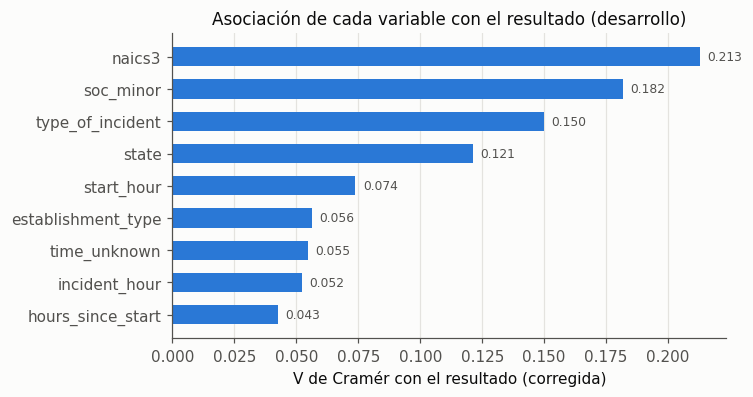

In [3]:
assoc = pd.Series({c: cramers_v(dev[c], y) for c in D.FEATURES}).sort_values()
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.barh([c for c in assoc.index], assoc.values, color=P.SERIES[0], height=0.6)
for i, v in enumerate(assoc.values):
    ax.text(v + 0.003, i, f'{v:.3f}', va='center', fontsize=8, color=P.INK2)
ax.set_xlabel('V de Cramér con el resultado (corregida)')
ax.set_title('Asociación de cada variable con el resultado (desarrollo)')
ax.grid(axis='y', visible=False)
P.save(fig, 'e3_eda_cramer'); plt.show()

**Interpretación.** El orden coincide con los entregables anteriores: el subsector y el grupo
ocupacional son lo más asociado con el resultado, seguidos por el tipo de incidente y el estado;
las variables de hora casi no aportan. Son asociaciones de a una variable: no dicen cuánto aporta
cada una cuando las demás ya están en el modelo (eso lo mide SHAP en el capítulo 11).

## 4.3 Variable nueva: horas desde el inicio de la jornada

Es la diferencia (módulo 24) entre la hora del incidente y la de inicio de la jornada, en
tramos. Los entregables anteriores la dejaron como siguiente paso. Es faltante cuando falta
cualquiera de las dos horas o la hora del incidente se reportó como desconocida.

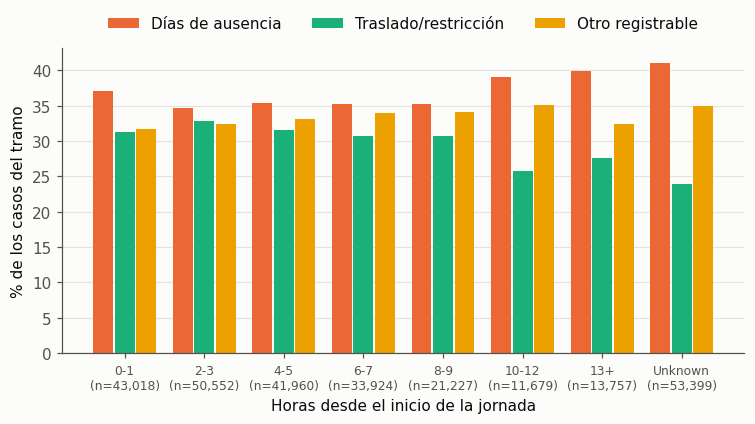

V de Cramér: 0.043


In [4]:
order = ['0-1', '2-3', '4-5', '6-7', '8-9', '10-12', '13+', 'Unknown']
tab = pd.crosstab(dev.hours_since_start, dev.y_clf, normalize='index').reindex(order) * 100
counts = dev.hours_since_start.value_counts().reindex(order)
fig, ax = plt.subplots(figsize=(8, 3.6))
x = np.arange(len(order)); w = 0.27
for j, k in enumerate([2, 3, 4]):
    ax.bar(x + (j - 1) * w, tab[k], width=w - 0.02, color=P.SERIES[j + 1], label=C.CLASS_NAMES[k - 1])
ax.set_xticks(x, [f'{o}\n(n={counts[o]:,})' for o in order], fontsize=8)
ax.set_ylabel('% de los casos del tramo'); ax.set_xlabel('Horas desde el inicio de la jornada')
ax.legend(ncol=3, loc='upper center', bbox_to_anchor=(0.5, 1.15)); ax.grid(axis='x', visible=False)
P.save(fig, 'e3_eda_horas_desde_inicio'); plt.show()
print('V de Cramér:', round(cramers_v(dev.hours_since_start, y), 3))

**Interpretación.** El 63 % de los incidentes con hora conocida ocurre en las primeras 8 horas de
la jornada. Hasta la hora 9 la mezcla de resultados casi no cambia (días de ausencia entre 35 % y
37 %). En jornadas largas (10 horas o más) y cuando falta la hora, sube la proporción de días de
ausencia (39 % a 41 %) y baja la de traslado o restricción (24 % a 28 %). Es una asociación
débil en conjunto (V = 0,043) y la categoría «Unknown» vuelve a mostrar que los faltantes de
hora no son al azar, por eso se conservan como categoría propia. Fallecimiento no se grafica
(69 casos en el desarrollo).

## 4.4 Objetivo de regresión: días de ausencia

La guía exige también 7 modelos de regresión. El único objetivo numérico del archivo que tiene
sentido con las mismas variables es **el número de días de ausencia** (`dafw_num_away`) de los
casos cuyo resultado es «días de ausencia». En clasificación esta columna se excluía porque
revela el resultado; en regresión es el objetivo, y se usa solo dentro de esa clase, así que no
hay fuga: la pregunta es *dado que el caso terminó en días de ausencia, cuántos días fueron*.

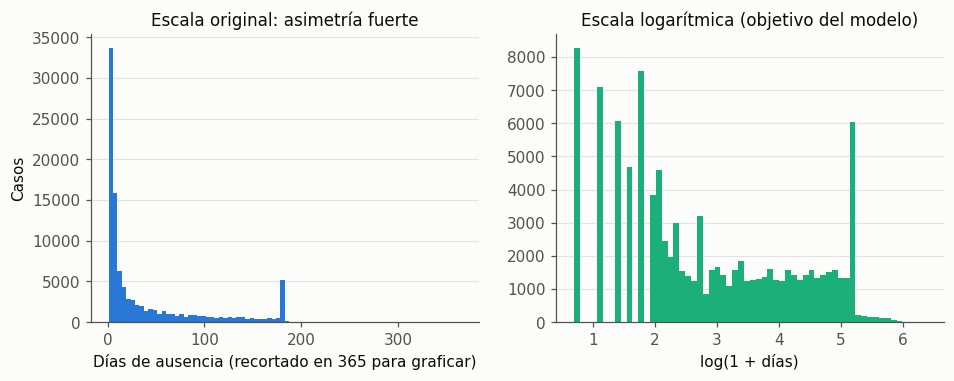

count    99074.0
mean        40.0
std         57.5
min          1.0
25%          4.0
50%         11.0
75%         52.0
90%        140.0
99%        195.0
max        587.0
Asimetría original: 1.87 | asimetría log1p: 0.34
Casos con más de 180 días: 1217 (1.2%)


In [5]:
r = dev[dev.y_reg.notna()]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
axes[0].hist(r.days_away.clip(upper=365), bins=80, color=P.SERIES[0])
axes[0].set_xlabel('Días de ausencia (recortado en 365 para graficar)'); axes[0].set_ylabel('Casos')
axes[0].set_title('Escala original: asimetría fuerte')
axes[1].hist(r.y_reg, bins=60, color=P.SERIES[2])
axes[1].set_xlabel('log(1 + días)'); axes[1].set_title('Escala logarítmica (objetivo del modelo)')
for a in axes: a.grid(axis='x', visible=False)
P.save(fig, 'e3_eda_dias'); plt.show()
desc = r.days_away.describe(percentiles=[.25, .5, .75, .9, .99])
print(desc.round(1).to_string())
print('Asimetría original:', round(stats.skew(r.days_away), 2), '| asimetría log1p:', round(stats.skew(r.y_reg), 2))
print('Casos con más de 180 días:', int((r.days_away > 180).sum()), f'({(r.days_away > 180).mean():.1%})')

**Interpretación.** Los días de ausencia son muy asimétricos (mediana 11, media 40, máximo 587).
La regla de registro de OSHA permite dejar de contar a los 180 días, pero el archivo tiene casos
por encima: no todas las empresas aplican el tope. Por la asimetría, el modelo predice
`log(1 + días)` (asimetría 1,87 → 0,34): los errores se miden en esa escala (un RMSE de 1
equivale a equivocarse por un factor de unas 2,7 veces en días). Dos rasgos del registro se ven
en la gráfica: los valores pequeños son enteros (1, 2, 3... días, por eso las barras sueltas a la
izquierda) y hay un pico en 180 días, el tope de la regla de OSHA (1,2 % de los casos supera ese
tope).

In [6]:
by_type = r.groupby('type_of_incident').days_away.agg(['count', 'median', 'mean']).round(1)
names = {'1': 'Lesión', '2': 'Trastorno de piel', '3': 'Respiratoria', '4': 'Envenenamiento',
         '5': 'Pérdida auditiva', '6': 'Otra enfermedad'}
by_type.index = [names.get(i, i) for i in by_type.index]
by_type.sort_values('count', ascending=False)

,count,median,mean
Lesión,84527,14.0,44.2
Respiratoria,9624,6.0,7.8
Otra enfermedad,3872,7.0,33.7
Trastorno de piel,583,7.0,15.0
Pérdida auditiva,382,16.0,44.0
Envenenamiento,86,4.5,19.9


**Interpretación.** Las lesiones son el 85 % de los casos con días de ausencia (mediana 14 días).
Las enfermedades respiratorias tienen ausencias mucho más cortas y homogéneas (mediana 6, media
7,8). Es una inferencia, no comprobada con este archivo, que se trate sobre todo de COVID-19
registrado como caso laboral. Encaja con el entregable 2, donde las respiratorias se asociaban
con muchas más posibilidades de terminar en días de ausencia: muchas ausencias, pero cortas.

## 4.5 Hallazgo durante el proyecto: la etiqueta de días está censurada

Al evaluar los modelos de regresión en la prueba (capítulo 10) apareció un sesgo que crecía mes a
mes. La causa se ve ya en los datos: un caso solo puede acumular días de ausencia hasta que se
cierra el reporte anual, así que los incidentes de fin de año no alcanzan ausencias largas. Se
muestra con **todos** los casos de 2023 con días de ausencia (desarrollo, prueba y casos
excluidos por la partición), porque es una propiedad del archivo, no de un modelo.

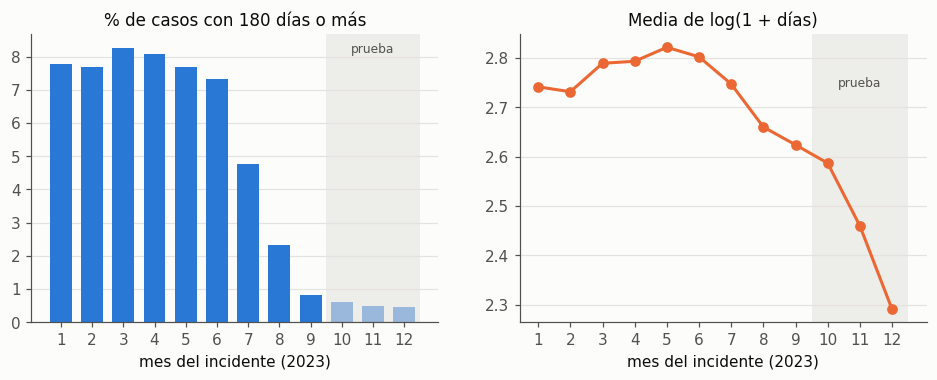

,casos,mediana_dias,media_log,pct_180
mes,,,,
1,30479,10.0,2.74,7.78
2,27079,10.0,2.73,7.69
3,28138,11.0,2.79,8.26
4,24638,12.0,2.79,8.08
5,25789,12.0,2.82,7.69
6,25375,12.0,2.80,7.31
7,26979,11.0,2.75,4.77
8,29925,10.0,2.66,2.33
9,26965,10.0,2.62,0.82


In [7]:
allr = df[df.y_reg.notna()].copy()
allr['mes'] = allr.date.dt.month
m = allr.groupby('mes').agg(casos=('y_reg', 'size'), mediana_dias=('days_away', 'median'),
                            media_log=('y_reg', 'mean'), pct_180=('days_away', lambda x: (x >= 180).mean() * 100))
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.4))
axes[0].bar(m.index, m.pct_180, color=P.SERIES[0], width=0.7)
axes[0].set_title('% de casos con 180 días o más'); axes[0].set_xlabel('mes del incidente (2023)')
axes[1].plot(m.index, m.media_log, marker='o', ms=6, color=P.SERIES[1])
axes[1].set_title('Media de log(1 + días)'); axes[1].set_xlabel('mes del incidente (2023)')
for a in axes:
    a.set_xticks(range(1, 13)); a.grid(axis='x', visible=False)
    a.axvspan(9.5, 12.5, color=P.GRID, alpha=0.6, lw=0); a.text(11, a.get_ylim()[1] * 0.97, 'prueba', ha='center', va='top', fontsize=8, color=P.INK2)
P.save(fig, 'e3_eda_censura'); plt.show()
m.round(2)

**Interpretación.** De enero a junio, alrededor del 8 % de los casos con días de ausencia llega al
tope de 180 días; desde julio la proporción cae (4,8 %, 2,3 %, 0,8 %) hasta el 0,5 % en diciembre,
y la media de log(1 + días) baja de ~2,8 a 2,29. No es que las lesiones de fin de año sean más
leves: a esos casos les faltó tiempo para acumular días antes del cierre del archivo. La etiqueta
está **censurada a la derecha** y la censura es más fuerte justo en el trimestre de prueba.

Consecuencias: (1) la clasificación no se ve afectada en la misma medida (basta un día de ausencia
para que el caso sea «días de ausencia»), aunque algún caso reciente podría figurar como
«traslado» u «otro» si su ausencia empezó tarde; (2) en regresión, cualquier modelo entrenado con
enero–septiembre sobrestima los días de octubre–diciembre (capítulo 10). Corregirlo bien exige un
modelo de supervivencia o restringir la evaluación a casos con seguimiento suficiente.

## 4.6 Corrección del entregable 1: `time_unknown` y la colinealidad

El profesor señaló que `time_unknown` superaba el umbral de colinealidad que el propio entregable
1 fijó (GVIF ajustado por grados de libertad de 3,80) y aun así se conservó sin discutirlo. Se
recalcula con las variables del entregable 3. El GVIF de un bloque de columnas one-hot j es
det(R_jj)·det(R_−j,−j)/det(R), con R la matriz de correlación de todas las columnas; se reporta
GVIF^(1/(2·gl)), comparable con √VIF.

In [8]:
from sklearn.preprocessing import OneHotEncoder
smp = dev.sample(60_000, random_state=C.SEED)
enc = OneHotEncoder(drop='first', min_frequency=200, handle_unknown='infrequent_if_exist', sparse_output=False).fit(smp[D.FEATURES])
Z = enc.transform(smp[D.FEATURES])
names_z = enc.get_feature_names_out(D.FEATURES)
keep = Z.std(axis=0) > 0
Z, names_z = Z[:, keep], names_z[keep]
R = np.corrcoef(Z, rowvar=False)
_, logdet_all = np.linalg.slogdet(R)
rows = []
for f in D.FEATURES:
    idx = np.array([n.startswith(f + '_') for n in names_z])
    _, a = np.linalg.slogdet(R[np.ix_(idx, idx)]); _, b = np.linalg.slogdet(R[np.ix_(~idx, ~idx)])
    gvif = np.exp(a + b - logdet_all); dfj = int(idx.sum())
    rows.append({'variable': f, 'gl (columnas)': dfj, 'GVIF': gvif, 'GVIF^(1/(2·gl))': gvif ** (1 / (2 * dfj))})
gv = pd.DataFrame(rows).set_index('variable').sort_values('GVIF^(1/(2·gl))', ascending=False)
display(gv.round(3))
print('Cruce time_unknown × hora del incidente desconocida (desarrollo):')
pd.crosstab(dev.time_unknown, dev.incident_hour.eq('Unknown'), margins=True)

,gl (columnas),GVIF,GVIF^(1/(2·gl))
variable,,,
time_unknown,2,210.830,3.811
hours_since_start,7,17.605,1.227
establishment_type,3,3.295,1.220
incident_hour,24,1285.136,1.161
naics3,38,14017.018,1.134
soc_minor,33,2619.537,1.127
start_hour,24,26.959,1.071
type_of_incident,5,1.409,1.035
state,41,2.545,1.011


Cruce time_unknown × hora del incidente desconocida (desarrollo):


incident_hour,False,True,All
time_unknown,,,
0,233123,55,233178
1,0,35786,35786
Unknown,116,436,552
All,233239,36277,269516


**Interpretación.** `time_unknown` sigue siendo, con diferencia, la variable más colineal (GVIF
ajustado 3,81; la siguiente es 1,23), por construcción: en los 35.786 casos con `time_unknown = 1`
la hora del incidente es «Unknown» (y `hours_since_start` también). No aporta
información propia; su contenido ya está en la categoría «Unknown» de la hora. Con el criterio
del entregable 1 debería salir del modelo. Para los modelos de este entregable (regularizados o de
árboles) la colinealidad no afecta la predicción, solo la interpretación de coeficientes y de
importancias, que se reparten entre las dos columnas redundantes. Se comprueba empíricamente en
el capítulo 12 (sección 12.5): quitar `time_unknown` y reajustar los 7 mejores modelos no cambia
el desempeño más allá del ruido. Por coherencia con el umbral fijado, la interpretación (capítulo 11)
se lee considerando ambas columnas como una sola fuente de información.

## 4.7 Corrección del entregable 1: el costo de los casos que el diseño descarta

El profesor observó que el diseño descarta cerca de la mitad de los casos sin discutir su costo.
La partición de los entregables 1 y 2 (que se mantiene) usa dos cortes a la vez: establecimientos
(40 % desarrollo, 60 % prueba) y tiempo (enero–septiembre para desarrollo, octubre–diciembre para
prueba, con 7 días de purga). Los casos que caen en el cruce «equivocado» no se usan.

In [9]:
dev_est = set(df.loc[df.split.eq('development'), 'establishment_id'])
cat = np.select([df.split.eq('development'), df.split.eq('test'),
                 df.date.ge('2023-09-24') & df.date.lt('2023-10-01'),
                 ~df.establishment_id.isin(dev_est) & df.date.lt('2023-09-24'),
                 df.establishment_id.isin(dev_est) & df.date.ge('2023-10-01')],
                ['Desarrollo (40 % establ., ene–23 sep)', 'Prueba (60 % establ., oct–dic)', 'Purga de 7 días (24–30 sep)',
                 'Descartado: establecimientos de prueba, ene–sep', 'Descartado: establecimientos de desarrollo, oct–dic'],
                'Descartado: otros (establecimientos solo en el periodo excluido)')
tab = pd.Series(cat).value_counts().to_frame('casos')
tab['%'] = tab.casos / len(df) * 100
tab.round(1)

,casos,%
"Descartado: establecimientos de prueba, ene–sep",388659,43.7
"Desarrollo (40 % establ., ene–23 sep)",269516,30.3
"Prueba (60 % establ., oct–dic)",127391,14.3
"Descartado: establecimientos de desarrollo, oct–dic",83912,9.4
Purga de 7 días (24–30 sep),17623,2.0
Descartado: otros (establecimientos solo en el periodo excluido),3271,0.4


**Interpretación.** Se usan 396.907 casos (44,6 %) y quedan fuera 493.465 (55,4 %). La mayor parte
del descarte (43,7 % del archivo) son los casos de enero a septiembre de los establecimientos
reservados para la prueba:
usarlos para entrenar haría que el modelo conociera esos establecimientos y la prueba dejaría de
medir la generalización a lugares nuevos (el riesgo de fuga que motivó la partición). El otro
bloque grande (9,4 %, 83.912 casos) son los casos de octubre a diciembre de los establecimientos de
desarrollo; la purga de 7 días suma un 2,0 %.

**Costo.** (1) *Menos datos para entrenar.* La curva de aprendizaje del entregable 2 mostró que
triplicar los datos casi no mejora la validación (0,377 → 0,385 de balanced accuracy), y en este
entregable los modelos se optimizan sobre una submuestra de 30.000 casos; el cuello de botella no es
la cantidad de casos sino la información de las variables. (2) *Menos casos raros:* se pierden
fallecimientos (69 en desarrollo, 39 en prueba, 172 descartados), lo que agrava el problema de esa
clase. (3) *Prueba más pequeña,* intervalos más anchos. **Beneficio:** una estimación honesta para
establecimientos y fechas nuevos. Además, el bloque descartado de octubre a diciembre de los
establecimientos de desarrollo sirve como una **segunda prueba** que solo separa por tiempo; en el
capítulo 9 (sección 9.8) se evalúan ahí los modelos para medir cuánto cuesta exigir establecimientos
nuevos.

## 4.8 Del EDA a la configuración del entregable 3

| Hallazgo | Decisión |
|---|---|
| NAICS/SOC completos: 1.433 columnas, mucha varianza | Subsector NAICS-3 y grupo menor SOC; categorías con < 20 casos → «infrequent» dentro del pipeline |
| Horas sin relación monótona; faltantes no aleatorios | Horas y tramos de horas desde el inicio como categorías con «Unknown» |
| Fallecimiento = 0,026 % | 4 clases; balanced accuracy como métrica de validación; SMOTE/ADASYN con vecinos ajustados a la clase minoritaria |
| Días de ausencia muy asimétricos | Objetivo de regresión `log1p(días)` |
| Días censurados por el cierre del archivo (más en oct–dic) | Leer la regresión en la prueba como comparación relativa; modelar la censura queda como siguiente paso |
| Casos agrupados por establecimiento | Todos los pliegues (externos e internos) separan establecimientos |